# Problema 2: Red Neuronal con Dos Capas Ocultas
### IMT2220 – Cálculo para Ciencia de Datos, 2026-2
---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Cargar datos
tarea_dir = '.'  # ajustar si es necesario
df  = pd.read_csv('datos_P2.csv')
dfg = pd.read_csv('datos_P2_g.csv')

x_data, y_data   = df['x'].values,  df['y'].values
xg_data, yg_data = dfg['x'].values, dfg['y'].values

N = len(x_data)
print(f'N = {N} datos de entrenamiento')
print(f'x en [{x_data.min():.4f}, {x_data.max():.4f}]')
print(f'y en [{y_data.min():.4f}, {y_data.max():.4f}]')

N = 200 datos de entrenamiento
x en [-0.9829, 0.9818]
y en [-0.2691, 2.3333]


---
## Parte (a): Derivada de la sigmoide

La función sigmoide es $\sigma(t) = \dfrac{1}{1 + e^{-t}}$.

### Demostración de $\sigma'(t) = \sigma(t)(1 - \sigma(t))$

Usando la regla del cociente con $u = 1$ y $v = 1 + e^{-t}$:
$$\sigma'(t) = \frac{0 \cdot (1+e^{-t}) - 1 \cdot (-e^{-t})}{(1+e^{-t})^2} = \frac{e^{-t}}{(1+e^{-t})^2}$$

Factorizamos:
$$\sigma'(t) = \frac{1}{1+e^{-t}} \cdot \frac{e^{-t}}{1+e^{-t}} = \frac{1}{1+e^{-t}} \cdot \frac{(1+e^{-t}) - 1}{1+e^{-t}} = \sigma(t)(1 - \sigma(t))$$

### Cota $0 < \sigma'(t) \leq \frac{1}{4}$

Sea $s = \sigma(t) \in (0,1)$ (ya que $1/(1+e^{-t})$ siempre está en $(0,1)$). Entonces:
$$\sigma'(t) = s(1-s)$$

Como $0 < s < 1$, tenemos $0 < s(1-s)$. Además, por la desigualdad AM-GM:
$$s(1-s) \leq \left(\frac{s + (1-s)}{2}\right)^2 = \frac{1}{4}$$
con igualdad si y solo si $s = 1-s$, es decir $s = 1/2$, lo que ocurre cuando $\sigma(t) = 1/2 \Leftrightarrow t = 0$.

Por lo tanto: $0 < \sigma'(t) \leq \frac{1}{4}$ para todo $t \in \mathbb{R}$, y el **máximo se alcanza en $t = 0$**.

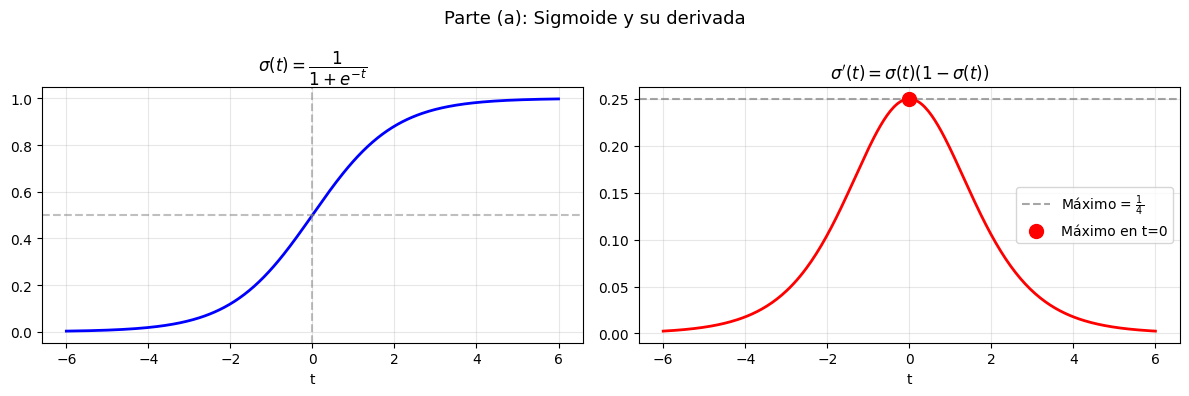

σ(0) = 0.5000
σ'(0) = 0.2500 = 1/4 ✓


In [2]:
def sigma(t):
    """Función sigmoide σ(t) = 1/(1 + exp(-t))."""
    return 1 / (1 + np.exp(-np.clip(t, -500, 500)))

def sigma_prime(t):
    """Derivada de σ: σ'(t) = σ(t)(1 - σ(t))."""
    s = sigma(t)
    return s * (1 - s)

t_vals = np.linspace(-6, 6, 300)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(t_vals, sigma(t_vals), 'b-', linewidth=2)
axes[0].set_title(r'$\sigma(t) = \dfrac{1}{1+e^{-t}}$')
axes[0].set_xlabel('t')
axes[0].axhline(0.5, color='gray', linestyle='--', alpha=0.5)
axes[0].axvline(0, color='gray', linestyle='--', alpha=0.5)
axes[0].grid(True, alpha=0.3)

axes[1].plot(t_vals, sigma_prime(t_vals), 'r-', linewidth=2)
axes[1].axhline(0.25, color='gray', linestyle='--', alpha=0.7, label=r'Máximo = $\frac{1}{4}$')
axes[1].scatter([0], [0.25], color='red', s=100, zorder=5, label='Máximo en t=0')
axes[1].set_title(r"$\sigma'(t) = \sigma(t)(1-\sigma(t))$")
axes[1].set_xlabel('t')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Parte (a): Sigmoide y su derivada', fontsize=13)
plt.tight_layout()
plt.savefig('fig_a_sigmoid.png', dpi=150)
plt.show()

print(f'σ(0) = {sigma(0):.4f}')
print(f"σ'(0) = {sigma_prime(0):.4f} = 1/4 ✓")

---
## Parte (b): Función de pérdida y su gradiente

La red tiene parámetros $\theta = (a_1, b_1, a_2, b_2, v, c) \in \mathbb{R}^6$. Para cada dato $(x_i, y_i)$ definimos:
$$z_{1,i} = a_1 x_i + b_1, \quad h_{1,i} = \sigma(z_{1,i})$$
$$z_{2,i} = a_2 h_{1,i} + b_2, \quad h_{2,i} = \sigma(z_{2,i})$$
$$\hat{y}_i = c + v h_{2,i}, \quad e_i = \hat{y}_i - y_i$$

La función de pérdida es:
$$J(\theta) = \frac{1}{2N} \sum_{i=1}^{N} e_i^2$$

### Cálculo del gradiente mediante la regla de la cadena (Clase 14, Ayudantía 7)

Usamos el grafo computacional para cada dato $i$. La pérdida individual es $L_i = \frac{1}{2}e_i^2$.

**Derivada respecto a $c$:** $c$ afecta $\hat{y}_i$ directamente:
$$\frac{\partial L_i}{\partial c} = e_i \cdot 1 = e_i$$

**Derivada respecto a $v$:** $v$ afecta $\hat{y}_i$ a través de $vh_{2,i}$:
$$\frac{\partial L_i}{\partial v} = e_i \cdot h_{2,i}$$

**Derivada respecto a $b_2$:** $b_2 \to z_{2,i} \to h_{2,i} \to \hat{y}_i \to L_i$:
$$\delta_{2,i} := \frac{\partial L_i}{\partial z_{2,i}} = e_i \cdot v \cdot \sigma'(z_{2,i})$$
$$\frac{\partial L_i}{\partial b_2} = \delta_{2,i} \cdot 1 = \delta_{2,i}$$

**Derivada respecto a $a_2$:** $a_2 \to z_{2,i} \to \ldots \to L_i$:
$$\frac{\partial L_i}{\partial a_2} = \delta_{2,i} \cdot h_{1,i}$$

**Propagamos hacia atrás a través de la primera capa:**
$$\delta_{1,i} := \frac{\partial L_i}{\partial z_{1,i}} = \delta_{2,i} \cdot a_2 \cdot \sigma'(z_{1,i})$$

**Derivada respecto a $b_1$:** $b_1 \to z_{1,i} \to \ldots \to L_i$:
$$\frac{\partial L_i}{\partial b_1} = \delta_{1,i}$$

**Derivada respecto a $a_1$:** $a_1 \to z_{1,i} \to \ldots \to L_i$:
$$\frac{\partial L_i}{\partial a_1} = \delta_{1,i} \cdot x_i$$

**Gradiente de $J$ (promedio sobre todos los datos):**
$$\nabla_\theta J(\theta) = \frac{1}{N}\sum_{i=1}^N \begin{pmatrix} \delta_{1,i} x_i \\ \delta_{1,i} \\ \delta_{2,i} h_{1,i} \\ \delta_{2,i} \\ e_i h_{2,i} \\ e_i \end{pmatrix}$$

donde $\delta_{2,i} = e_i v \sigma'(z_{2,i})$ y $\delta_{1,i} = \delta_{2,i} a_2 \sigma'(z_{1,i})$.

---
## Parte (c): Implementación y verificación del gradiente

In [3]:
def forward(x, theta):
    """Propagación hacia adelante de la red para entradas vectorizadas."""
    a1, b1, a2, b2, v, c = theta
    z1 = a1 * x + b1
    h1 = sigma(z1)
    z2 = a2 * h1 + b2
    h2 = sigma(z2)
    y_hat = c + v * h2
    return y_hat, z1, h1, z2, h2

def compute_loss(theta, x_data, y_data):
    """Función de pérdida J(θ) = (1/2N) Σ (ŷ_i - y_i)²."""
    y_hat, _, _, _, _ = forward(x_data, theta)
    e = y_hat - y_data
    return 0.5 * np.mean(e**2)

def compute_gradient(theta, x_data, y_data):
    """Gradiente ∇_θ J(θ) calculado analíticamente con la regla de la cadena."""
    a1, b1, a2, b2, v, c = theta
    y_hat, z1, h1, z2, h2 = forward(x_data, theta)
    e = y_hat - y_data          # error por dato
    
    # Retropropagación
    delta2 = e * v * sigma_prime(z2)    # ∂L_i/∂z_{2,i}
    delta1 = delta2 * a2 * sigma_prime(z1)  # ∂L_i/∂z_{1,i}
    
    da1 = np.mean(delta1 * x_data)
    db1 = np.mean(delta1)
    da2 = np.mean(delta2 * h1)
    db2 = np.mean(delta2)
    dv  = np.mean(e * h2)
    dc  = np.mean(e)
    
    return np.array([da1, db1, da2, db2, dv, dc])

# Inicialización θ₀ con semilla fija
np.random.seed(42)
theta0 = np.random.uniform(-1, 1, 6)
print(f'θ₀ = {theta0}')

J0 = compute_loss(theta0, x_data, y_data)
print(f'J(θ₀) = {J0:.6f}')

θ₀ = [-0.25091976  0.90142861  0.46398788  0.19731697 -0.68796272 -0.68801096]
J(θ₀) = 3.150828


In [4]:
# Verificación del gradiente con diferencias centradas
h_fd = 1e-5
grad_anal = compute_gradient(theta0, x_data, y_data)
grad_fd   = np.zeros(6)
param_names = ['a₁', 'b₁', 'a₂', 'b₂', 'v', 'c']

for j in range(6):
    ej = np.zeros(6); ej[j] = 1.0
    grad_fd[j] = (compute_loss(theta0 + h_fd*ej, x_data, y_data)
                - compute_loss(theta0 - h_fd*ej, x_data, y_data)) / (2*h_fd)

E = np.max(np.abs(grad_anal - grad_fd))

print(f"{'Parámetro':<10} {'Analítico':>15} {'Dif. Centradas':>17} {'Error abs':>12}")
print('-' * 58)
for j in range(6):
    err = abs(grad_anal[j] - grad_fd[j])
    print(f"{param_names[j]:<10} {grad_anal[j]:15.10f} {grad_fd[j]:17.10f} {err:12.2e}")
print(f'\nError máximo E = {E:.2e}  (esperado: del orden de h² = {h_fd**2:.2e})')

Parámetro        Analítico    Dif. Centradas    Error abs
----------------------------------------------------------
a₁            0.0082217484      0.0082217484     1.00e-11
b₁            0.0362284884      0.0362284885     3.13e-11
a₂            0.2612270505      0.2612270505     9.50e-12
b₂            0.3731255768      0.3731255768     1.81e-11
v            -1.4566714937     -1.4566714936     1.45e-11
c            -2.3208098450     -2.3208098450     1.38e-11

Error máximo E = 3.13e-11  (esperado: del orden de h² = 1.00e-10)


---
## Parte (d): Descenso del gradiente con α = 1, 20.000 iteraciones

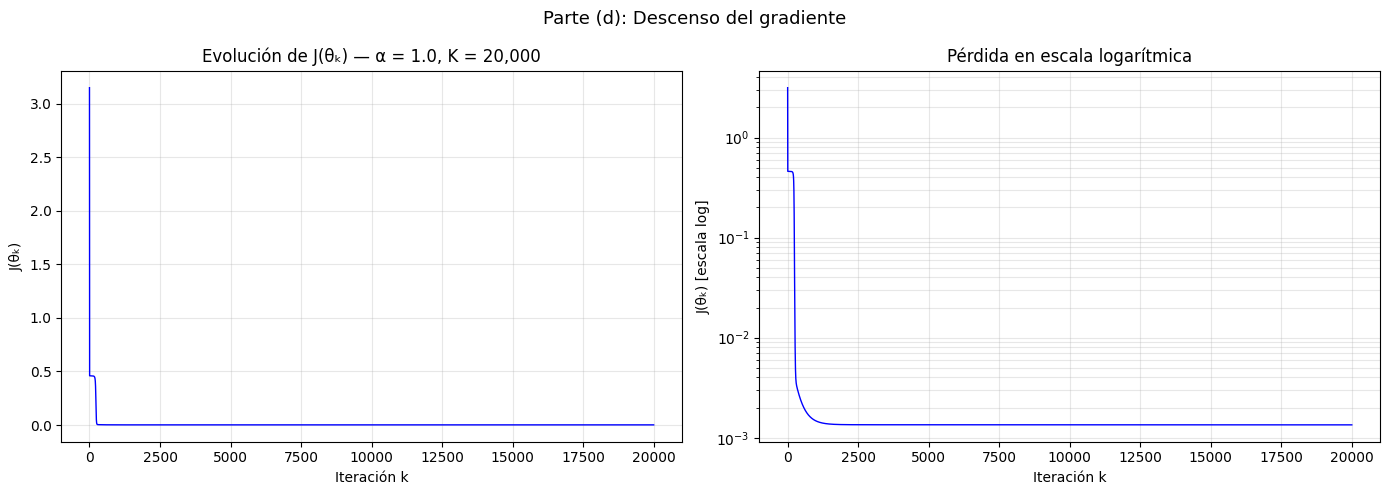

J(θ₀) = 3.150828
J(θ₂₀₀₀₀) = 0.001344
Pérdida en iteraciones seleccionadas:
  k =      0:  J = 3.150828
  k =     10:  J = 0.459945
  k =    100:  J = 0.459042
  k =   1000:  J = 0.001474
  k =  10000:  J = 0.001346
  k =  20000:  J = 0.001344

Plateau ½·Var(y) = 0.459726


In [5]:
def gradient_descent(theta_init, x_data, y_data, alpha, K):
    """Ejecuta K iteraciones de descenso del gradiente con paso fijo alpha."""
    theta = theta_init.copy()
    losses = []
    for k in range(K):
        losses.append(compute_loss(theta, x_data, y_data))
        grad  = compute_gradient(theta, x_data, y_data)
        theta = theta - alpha * grad
    losses.append(compute_loss(theta, x_data, y_data))  # pérdida final
    return theta, np.array(losses)

K = 20000
alpha = 1.0

theta_final, losses_hist = gradient_descent(theta0, x_data, y_data, alpha, K)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Curva de pérdida completa
axes[0].plot(losses_hist, 'b-', linewidth=1)
axes[0].set_xlabel('Iteración k')
axes[0].set_ylabel('J(θₖ)')
axes[0].set_title(f'Evolución de J(θₖ) — α = {alpha}, K = {K:,}')
axes[0].grid(True, alpha=0.3)

# Log-scale
axes[1].semilogy(losses_hist, 'b-', linewidth=1)
axes[1].set_xlabel('Iteración k')
axes[1].set_ylabel('J(θₖ) [escala log]')
axes[1].set_title('Pérdida en escala logarítmica')
axes[1].grid(True, alpha=0.3, which='both')

plt.suptitle('Parte (d): Descenso del gradiente', fontsize=13)
plt.tight_layout()
plt.savefig('fig_d_loss.png', dpi=150)
plt.show()

print(f'J(θ₀) = {losses_hist[0]:.6f}')
print(f'J(θ₂₀₀₀₀) = {losses_hist[-1]:.6f}')
print('Pérdida en iteraciones seleccionadas:')
for k in [0, 10, 100, 1000, 10000, 20000]:
    print(f'  k = {k:>6}:  J = {losses_hist[k]:.6f}')
print(f'\nPlateau ½·Var(y) = {0.5*np.var(y_data):.6f}')


### Comentario sobre la forma de la curva (d)

La curva de $J$ no es una recta en escala log. Tiene tres fases:
1. **Caída rápida** en las primeras ~10 iteraciones: de $J\approx 3.15$ a $\approx 0.46$.
2. **Meseta** en $J\approx 0.46$, que es exactamente $\tfrac12\mathrm{Var}(y)$: la red predice la media $\bar y \approx 1.20$ y no logra aún usar la variación de $x$. La meseta dura desde $k\approx 10$ hasta algún punto entre $k\approx100$ y $k\approx1000$.
3. **Salto** a $J\approx 0.0015$ y después **convergencia lenta** hasta $J\approx 0.001344$: los últimos ~19 000 pasos sólo mejoran la cuarta cifra.

El descenso del gradiente termina en una zona donde $J$ ya casi no baja, pero la meseta muestra que pasa por un punto de $J$ muy alto antes de encontrar la pendiente útil.

---
## Parte (e): Parámetros finales y visualización del ajuste

θ₂₀₀₀₀ = (a₁, b₁, a₂, b₂, v, c):
  a₁ = -4.919496
  b₁ = -1.052485
  a₂ = -3.542702
  b₂ = 1.654625
  v  = 3.411599
  c  = -0.655842

J(θ₂₀₀₀₀) = 0.001344


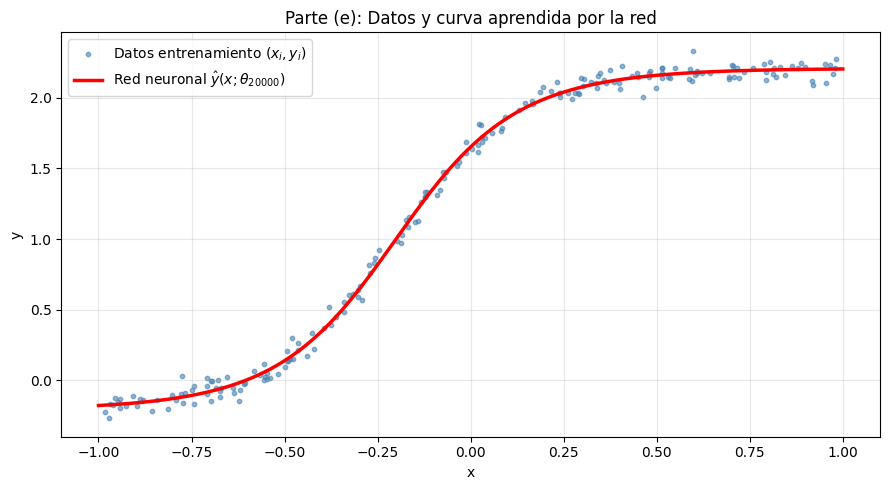

In [6]:
a1f, b1f, a2f, b2f, vf, cf = theta_final
print('θ₂₀₀₀₀ = (a₁, b₁, a₂, b₂, v, c):')
print(f'  a₁ = {a1f:.6f}')
print(f'  b₁ = {b1f:.6f}')
print(f'  a₂ = {a2f:.6f}')
print(f'  b₂ = {b2f:.6f}')
print(f'  v  = {vf:.6f}')
print(f'  c  = {cf:.6f}')
print(f'\nJ(θ₂₀₀₀₀) = {losses_hist[-1]:.6f}')

# Graficar datos vs curva ajustada
x_plot = np.linspace(-1, 1, 500)
y_hat_plot, _, _, _, _ = forward(x_plot, theta_final)

plt.figure(figsize=(9, 5))
plt.scatter(x_data, y_data, s=10, alpha=0.6, label='Datos entrenamiento $(x_i, y_i)$', color='steelblue')
plt.plot(x_plot, y_hat_plot, 'r-', linewidth=2.5, label=r'Red neuronal $\hat{y}(x; \theta_{20000})$')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Parte (e): Datos y curva aprendida por la red')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig_e_fit.png', dpi=150)
plt.show()

---
## Parte (f): Sensibilidad del entrenamiento

### (f.i) Diferentes valores del paso α

α=0.01: J_final=0.458889


α=0.1: J_final=0.001351


α=1.0: J_final=0.001344


C:\Users\ThinkPad\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\_core\_methods.py:134: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_9440\4280609119.py:15: RuntimeWarning: overflow encountered in square
  return 0.5 * np.mean(e**2)
C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_9440\4280609119.py:24: RuntimeWarning: overflow encountered in multiply
  delta2 = e * v * sigma_prime(z2)    # ∂L_i/∂z_{2,i}
C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_9440\4280609119.py:25: RuntimeWarning: invalid value encountered in multiply
  delta1 = delta2 * a2 * sigma_prime(z1)  # ∂L_i/∂z_{1,i}


α=2.5: J_final=nan


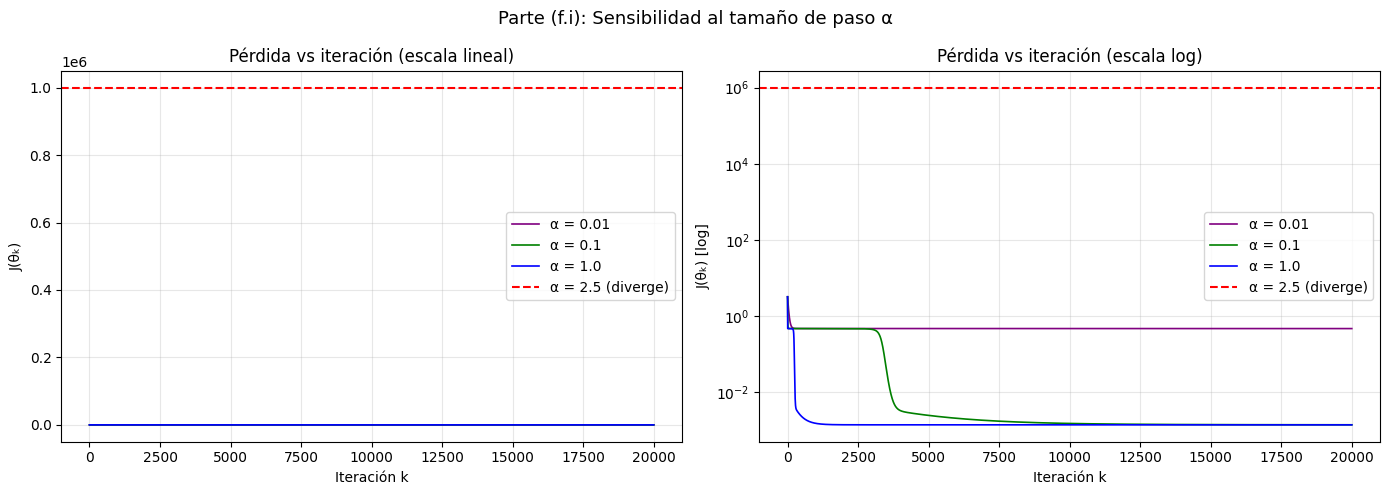


Plateau de predicción constante: ½·Var(y) = 0.459726


In [7]:
alphas = [0.01, 0.1, 1.0, 2.5]
colors = ['purple', 'green', 'blue', 'red']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for alpha, color in zip(alphas, colors):
    _, ls = gradient_descent(theta0, x_data, y_data, alpha, K)
    if not np.any(np.isnan(ls)) and not np.any(np.isinf(ls)):
        axes[0].plot(ls, color=color, linewidth=1.2, label=f'α = {alpha}')
        axes[1].semilogy(ls, color=color, linewidth=1.2, label=f'α = {alpha}')
    else:
        axes[0].axhline(y=1e6, color=color, linestyle='--', label=f'α = {alpha} (diverge)')
        axes[1].axhline(y=1e6, color=color, linestyle='--', label=f'α = {alpha} (diverge)')
    print(f'α={alpha}: J_final={ls[-1]:.6f}')

for ax in axes:
    ax.set_xlabel('Iteración k')
    ax.legend()
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel('J(θₖ)')
axes[0].set_title('Pérdida vs iteración (escala lineal)')
axes[1].set_ylabel('J(θₖ) [log]')
axes[1].set_title('Pérdida vs iteración (escala log)')

plt.suptitle('Parte (f.i): Sensibilidad al tamaño de paso α', fontsize=13)
plt.tight_layout()
plt.savefig('fig_f_i_alphas.png', dpi=150)
plt.show()

print(f'\nPlateau de predicción constante: ½·Var(y) = {0.5*np.var(y_data):.6f}')


### Interpretación de (f.i)

- **$\alpha = 0.01$**: $J_{\text{final}} \approx 0.4589$, prácticamente en la meseta $\tfrac12\mathrm{Var}(y) \approx 0.4597$. Con 20 000 pasos no sale de ella. No es "convergencia lenta y estable": no converge en el número de iteraciones dado.
- **$\alpha = 0.1$**: $J_{\text{final}} \approx 0.00135$. Converge, con un poco más de lentitud que $\alpha=1$.
- **$\alpha = 1$**: $J_{\text{final}} \approx 0.00134$, el mejor de los cuatro.
- **$\alpha = 2.5$**: la pérdida se vuelve NaN por desbordamiento. El paso supera el límite de estabilidad del descenso del gradiente para esta función, así que los iterados crecen sin control.

Un paso pequeño es estable pero lento, y uno grande es rápido pero diverge. El valor intermedio $\alpha=1$ es el que mejor equilibra ambas cosas.

### (f.ii) Diferentes inicializaciones en [-1,1] y [-5,5]

In [8]:
alpha = 1.0
J_finals_11 = []
J_finals_55 = []

print('Inicializaciones en [-1, 1]:')
for seed in range(10):
    np.random.seed(seed)
    theta_s = np.random.uniform(-1, 1, 6)
    theta_s_final, _ = gradient_descent(theta_s, x_data, y_data, alpha, K)
    Jf = compute_loss(theta_s_final, x_data, y_data)
    J_finals_11.append(Jf)
    print(f'  Semilla {seed}: J_final = {Jf:.6f}')

print('\nInicializaciones en [-5, 5]:')
for seed in range(10):
    np.random.seed(seed)
    theta_s = np.random.uniform(-5, 5, 6)
    theta_s_final, _ = gradient_descent(theta_s, x_data, y_data, alpha, K)
    Jf = compute_loss(theta_s_final, x_data, y_data)
    J_finals_55.append(Jf)
    print(f'  Semilla {seed}: J_final = {Jf:.6f}')

Inicializaciones en [-1, 1]:


  Semilla 0: J_final = 0.001347


  Semilla 1: J_final = 0.001345


  Semilla 2: J_final = 0.001345


  Semilla 3: J_final = 0.001344


...

  Semilla 5: J_final = 0.001356


  Semilla 6: J_final = 0.459738


  Semilla 7: J_final = 0.001340


  Semilla 8: J_final = 0.001335


  Semilla 9: J_final = 0.001341


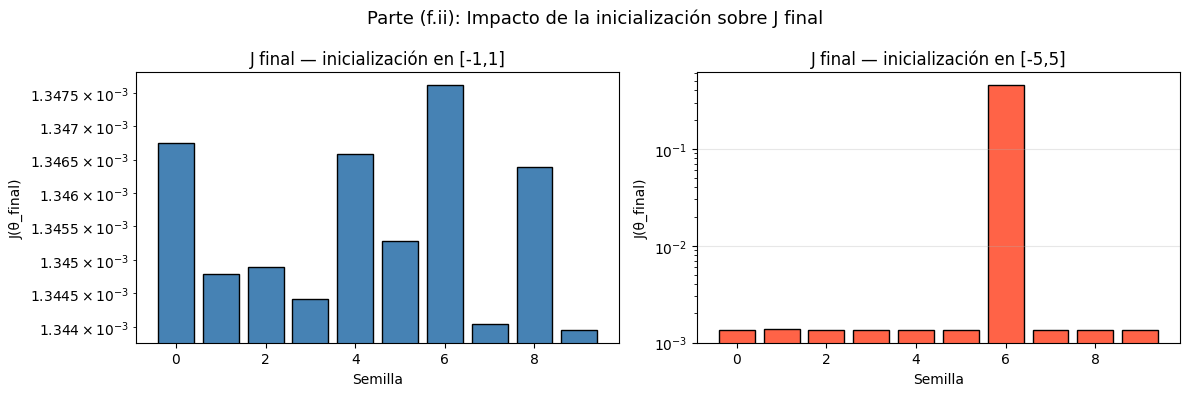


Plateau ½·Var(y) = 0.459726
Corridas en [-1,1] con J < 0.01: 10/10
Corridas en [-5,5] con J < 0.01: 9/10
Corridas en [-5,5] atrapadas en la meseta (|J − ½Var(y)| < 1e-3): 1/10


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(10), J_finals_11, color='steelblue', edgecolor='black')
axes[0].set_title('J final — inicialización en [-1,1]')
axes[0].set_xlabel('Semilla'); axes[0].set_ylabel('J(θ_final)')
axes[0].set_yscale('log'); axes[0].grid(True, alpha=0.3, axis='y')

axes[1].bar(range(10), J_finals_55, color='tomato', edgecolor='black')
axes[1].set_title('J final — inicialización en [-5,5]')
axes[1].set_xlabel('Semilla'); axes[1].set_ylabel('J(θ_final)')
axes[1].set_yscale('log'); axes[1].grid(True, alpha=0.3, axis='y')

plt.suptitle('Parte (f.ii): Impacto de la inicialización sobre J final', fontsize=13)
plt.tight_layout()
plt.savefig('fig_f_ii_init.png', dpi=150)
plt.show()

# Diagnóstico numérico de cada corrida
J_plateau = 0.5 * np.var(y_data)
print(f'\nPlateau ½·Var(y) = {J_plateau:.6f}')
print(f'Corridas en [-1,1] con J < 0.01: {sum(j < 0.01 for j in J_finals_11)}/10')
print(f'Corridas en [-5,5] con J < 0.01: {sum(j < 0.01 for j in J_finals_55)}/10')
print(f'Corridas en [-5,5] atrapadas en la meseta (|J − ½Var(y)| < 1e-3): '
      f'{sum(abs(j - J_plateau) < 1e-3 for j in J_finals_55)}/10')


### Interpretación de (f.ii)

**Respuesta corta:** no. Con $[-1,1]$, las 10 corridas llegan a $J\approx 0.00134$–$0.00135$; las diferencias en la cuarta cifra indican que 20 000 iteraciones no alcanzan el mínimo exacto. Con $[-5,5]$, 9 de 10 corridas llegan a $J\approx 0.00134$–$0.00137$, pero la semilla 6 se queda en $J\approx 0.4597$.

**Qué pasa en la semilla 6.** Ese valor es exactamente $\tfrac12\mathrm{Var}(y)$, la pérdida de la red que predice la media constante. En el $\theta$ final, la segunda neurona queda saturada en $\approx 0$ para todo $x$ ($z_2 \approx -7.7$, $\sigma'(z_2)\approx 0.0004$), así que $\hat y \approx c \approx \bar y$. El gradiente es $\approx 3\cdot 10^{-5}$ y el descenso prácticamente no se mueve.

**Lo que esto dice del método.** La saturación al inicio no basta para quedar atrapado: varias semillas con $|z|$ grande también convergen. Lo que importa es si la red llega a una región donde la sigmoide queda plana para todo $x$, porque ahí el gradiente deja de guiar el descenso. El método sólo garantiza un punto crítico ($\nabla J = 0$), y aquí ese punto es una meseta de pérdida alta, no el mínimo global.

---
## Parte (g): Ajuste a una función distinta $\tilde{f}$

### (g.i) Entrenamiento con los datos $(x_i, \tilde{y}_i)$

θ_g final = [-6.44229437 -3.22835191  4.21653997 -4.33172431  5.56652298  0.24854319]
J(θ_g) = 0.069287


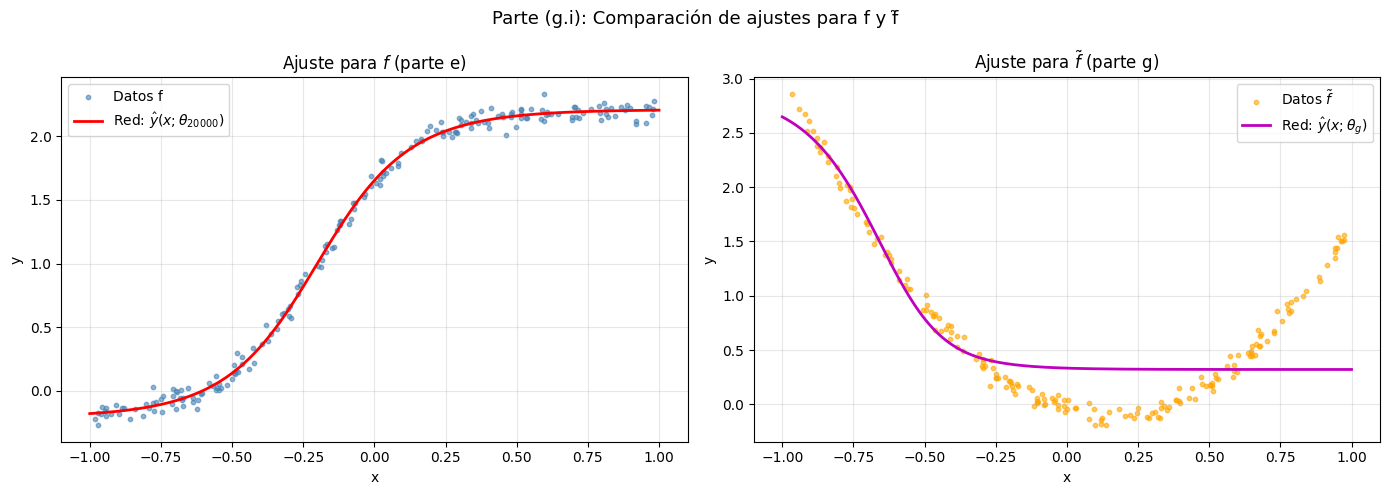

In [10]:
theta_g, losses_g = gradient_descent(theta0, xg_data, yg_data, alpha=1.0, K=20000)

print(f'θ_g final = {theta_g}')
print(f'J(θ_g) = {losses_g[-1]:.6f}')

x_plot = np.linspace(-1, 1, 500)
y_hat_f,  _, _, _, _ = forward(x_plot, theta_final)
y_hat_g,  _, _, _, _ = forward(x_plot, theta_g)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Datos f (parte e)
axes[0].scatter(x_data, y_data, s=10, alpha=0.6, color='steelblue', label='Datos f')
axes[0].plot(x_plot, y_hat_f, 'r-', linewidth=2, label=r'Red: $\hat{y}(x; \theta_{20000})$')
axes[0].set_title('Ajuste para $f$ (parte e)')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

# Datos f tilde (parte g)
axes[1].scatter(xg_data, yg_data, s=10, alpha=0.6, color='orange', label=r'Datos $\tilde{f}$')
axes[1].plot(x_plot, y_hat_g, 'm-', linewidth=2, label=r'Red: $\hat{y}(x; \theta_g)$')
axes[1].set_title(r'Ajuste para $\tilde{f}$ (parte g)')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

for ax in axes:
    ax.set_xlabel('x'); ax.set_ylabel('y')

plt.suptitle('Parte (g.i): Comparación de ajustes para f y f̃', fontsize=13)
plt.tight_layout()
plt.savefig('fig_g_i_fit.png', dpi=150)
plt.show()

### Respuesta a (g.i)

**No**, la red no logra ajustar estos datos. El error final es $J(\theta_g)\approx 0.069$, unas 50 veces el de $f$ ($J\approx 0.0013$). En la figura, la curva ajustada es decreciente en todo $[-1,1]$, mientras los datos bajan hasta $x\approx 0.1$ y luego vuelven a subir. La red sólo captura la rama izquierda.

### (g.ii) ¿Por qué la red no puede aproximar bien $\tilde f$?

**Monotonía de la red.** Por la regla de la cadena,
$$\frac{d\hat y}{dx} = v\, a_1 a_2\, \sigma'(z_1)\, \sigma'(z_2).$$
Como $\sigma'>0$, el signo de $\frac{d\hat y}{dx}$ es el de $v a_1 a_2$, que no depende de $x$. Por tanto $x\mapsto \hat y(x;\theta)$ es **monótona** (creciente o decreciente para cualquier $\theta$; sólo sería constante en el caso degenerado $v a_1 a_2 = 0$). Además, $h_2\in(0,1)$ implica $\hat y\in(c, c+v)$ si $v>0$, o $\hat y\in(c+v, c)$ si $v<0$.

**Lo que muestran los datos.** Los datos de $\tilde f$ no son monótonos. Promediando $\tilde y$ por intervalos de $x$ (celda siguiente) se obtiene $\approx 2.27$ en $x\in[-1,-0.75)$, $\approx -0.09$ en $x\in[0,0.25)$ y $\approx 1.19$ en $x\in[0.75,1]$. Es una forma de "V": primero baja y luego sube.

**Conclusión.** Una función monótona no puede seguir una "V". Por eso el mejor $\theta$ produce una curva decreciente que sólo ajusta la rama izquierda ($J\approx 0.069$). Esta es una limitación **estructural** de la arquitectura (una neurona por capa), no del entrenamiento: ni $\alpha$, ni el número de iteraciones, ni la inicialización cambian la conclusión. Para representar $\tilde f$ haría falta más flexibilidad, por ejemplo más de una neurona en la primera capa.

In [11]:
# Evidencia de no monotonía: promedio de ỹ por intervalos de x
bins = np.linspace(-1, 1, 9)
idx = np.digitize(xg_data, bins)
for k in range(1, len(bins)):
    m = idx == k
    if m.any():
        print(f'x ∈ [{bins[k-1]:+.2f}, {bins[k]:+.2f}):  media de ỹ = {yg_data[m].mean():+.3f}   (n = {m.sum()})')

x ∈ [-1.00, -0.75):  media de ỹ = +2.272   (n = 23)
x ∈ [-0.75, -0.50):  media de ỹ = +1.372   (n = 20)
x ∈ [-0.50, -0.25):  media de ỹ = +0.606   (n = 29)
x ∈ [-0.25, +0.00):  media de ỹ = +0.101   (n = 34)
x ∈ [+0.00, +0.25):  media de ỹ = -0.089   (n = 18)
x ∈ [+0.25, +0.50):  media de ỹ = +0.015   (n = 23)
x ∈ [+0.50, +0.75):  media de ỹ = +0.429   (n = 32)
x ∈ [+0.75, +1.00):  media de ỹ = +1.193   (n = 21)


Signo de v·a1·a2 = -151.2101
dy/dx mínimo = -5.1487, máximo = -0.0001
=> La función es decreciente en todo [-1,1]


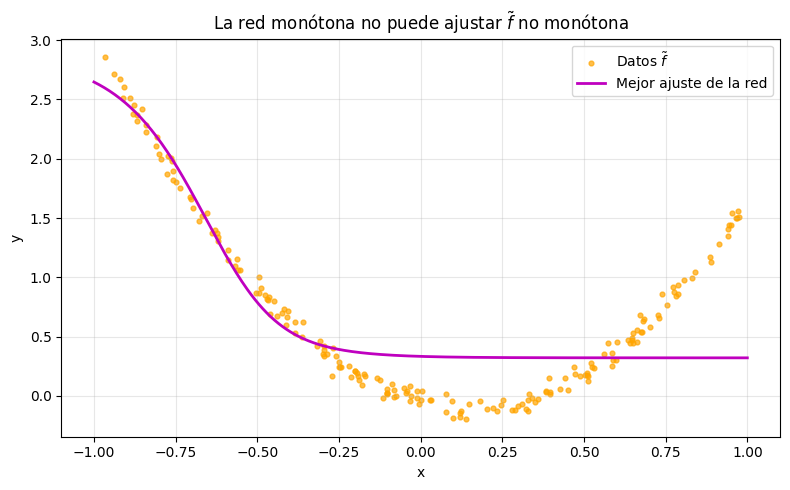


Conclusión:
Los datos de f̃ muestran una función NO monótona en [-1,1].
La red con esta arquitectura (dos capas ocultas de 1 neurona, sigmoide)
solo puede representar funciones monótonas con valores en (c, c+v).
Por la demostración, dy/dx tiene signo constante para CUALQUIER θ.
Ninguna inicialización ni número de iteraciones cambia esta limitación estructural.


In [12]:
# Verificar monotonía numéricamente
x_plot = np.linspace(-1, 1, 500)
y_hat_g_plot, z1_g, _, z2_g, _ = forward(x_plot, theta_g)
a1g, b1g, a2g, b2g, vg, cg = theta_g

dy_dx = vg * a1g * a2g * sigma_prime(z1_g) * sigma_prime(z2_g)
print(f'Signo de v·a1·a2 = {vg*a1g*a2g:.4f}')
print(f'dy/dx mínimo = {dy_dx.min():.4f}, máximo = {dy_dx.max():.4f}')
print(f'=> La función es {"creciente" if (dy_dx > 0).all() else "decreciente"} en todo [-1,1]')

# Datos de f_tilde: ¿son monótonos?
plt.figure(figsize=(8, 5))
plt.scatter(xg_data, yg_data, s=12, alpha=0.7, color='orange', label=r'Datos $\tilde{f}$')
plt.plot(x_plot, y_hat_g_plot, 'm-', linewidth=2, label='Mejor ajuste de la red')
plt.xlabel('x'); plt.ylabel('y')
plt.title(r'La red monótona no puede ajustar $\tilde{f}$ no monótona')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig_g_ii_monotone.png', dpi=150)
plt.show()

print('\nConclusión:')
print(f'Los datos de f̃ muestran una función NO monótona en [-1,1].')
print('La red con esta arquitectura (dos capas ocultas de 1 neurona, sigmoide)')
print('solo puede representar funciones monótonas con valores en (c, c+v).')
print('Por la demostración, dy/dx tiene signo constante para CUALQUIER θ.')
print('Ninguna inicialización ni número de iteraciones cambia esta limitación estructural.')